# A system of ODEs: Method 3 - using SciPy's ```solve_ivp```

In [1]:
# our standard import
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format='retina' # hi-res plots for a Retina display
# import solve_ivp
from scipy.integrate import solve_ivp

## A predator-prey relationship for Rabbits and Foxes

The predator-prey relationship is a classic coupled ODE system. Here we describe the coupled population dynamics of rabbits, $R$, and foxes, $F$, with the following:

\begin{align}
\frac{dR}{dt} &= aR-bRF \\
\frac{dF}{dt} &= -lF+kRF 
\end{align}

where $R$ and $F$ are the population values of rabbits and foxes. The coefficients are defined as:

\begin{align}
a &= \text{base birth rate of rabits}  \\
b &= \text{prey factor}  \\
l &= \text{fox base diminishing rate}\\
k &= \text{feeding rate}
\end{align}

This coupled system of equations is solved below using SciPy's ```solve_ivp``` (for more information see the [SciPy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)). By default it uses an adaptive Runge-Kutta method (`RK45`, Dormand-Prince). Note that the right-hand side takes the independent variable first, `f(t, y)`, just like our hand-written RK4.

## Method 3: using SciPy ```solve_ivp```

In [2]:
# --- User input ------------

# define the ODE system of equations
def df(t, ic): # the independent variable comes first, then the state
    R, F = ic[0], ic[1]
    dR = a*R - b*R*F
    dF = -l*F + k*R*F
    return [dR, dF]

# define the start and stop locations and the output spacing
start = 0
end = 50
dt = 0.01
R_0 = 500
F_0 = 100

# define the coefficients
a = 0.5   # base birth rate of rabbits
b = 0.01  # prey factor
l = 1     # fox base diminishing rate
k = 0.005 # feeding rate

# --- Calculations ------------

# times at which we want the solution reported
t = np.arange(start, end, dt)

# set the initial conditions
ic = [R_0, F_0]

# solve using solve_ivp: (function, (t_start, t_end), initial conditions, t_eval=...)
sol = solve_ivp(df, (start, end), ic, t_eval=t)

In [3]:
# look at the solution (sol.t are the times, sol.y the values)
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.000e-02 ...  4.998e+01  4.999e+01]
        y: [[ 5.000e+02  4.975e+02 ...  1.838e+02  1.847e+02]
            [ 1.000e+02  1.015e+02 ...  4.036e+00  4.033e+00]]
      sol: None
 t_events: None
 y_events: None
     nfev: 392
     njev: 0
      nlu: 0

In [4]:
sol.y.shape

(2, 5000)

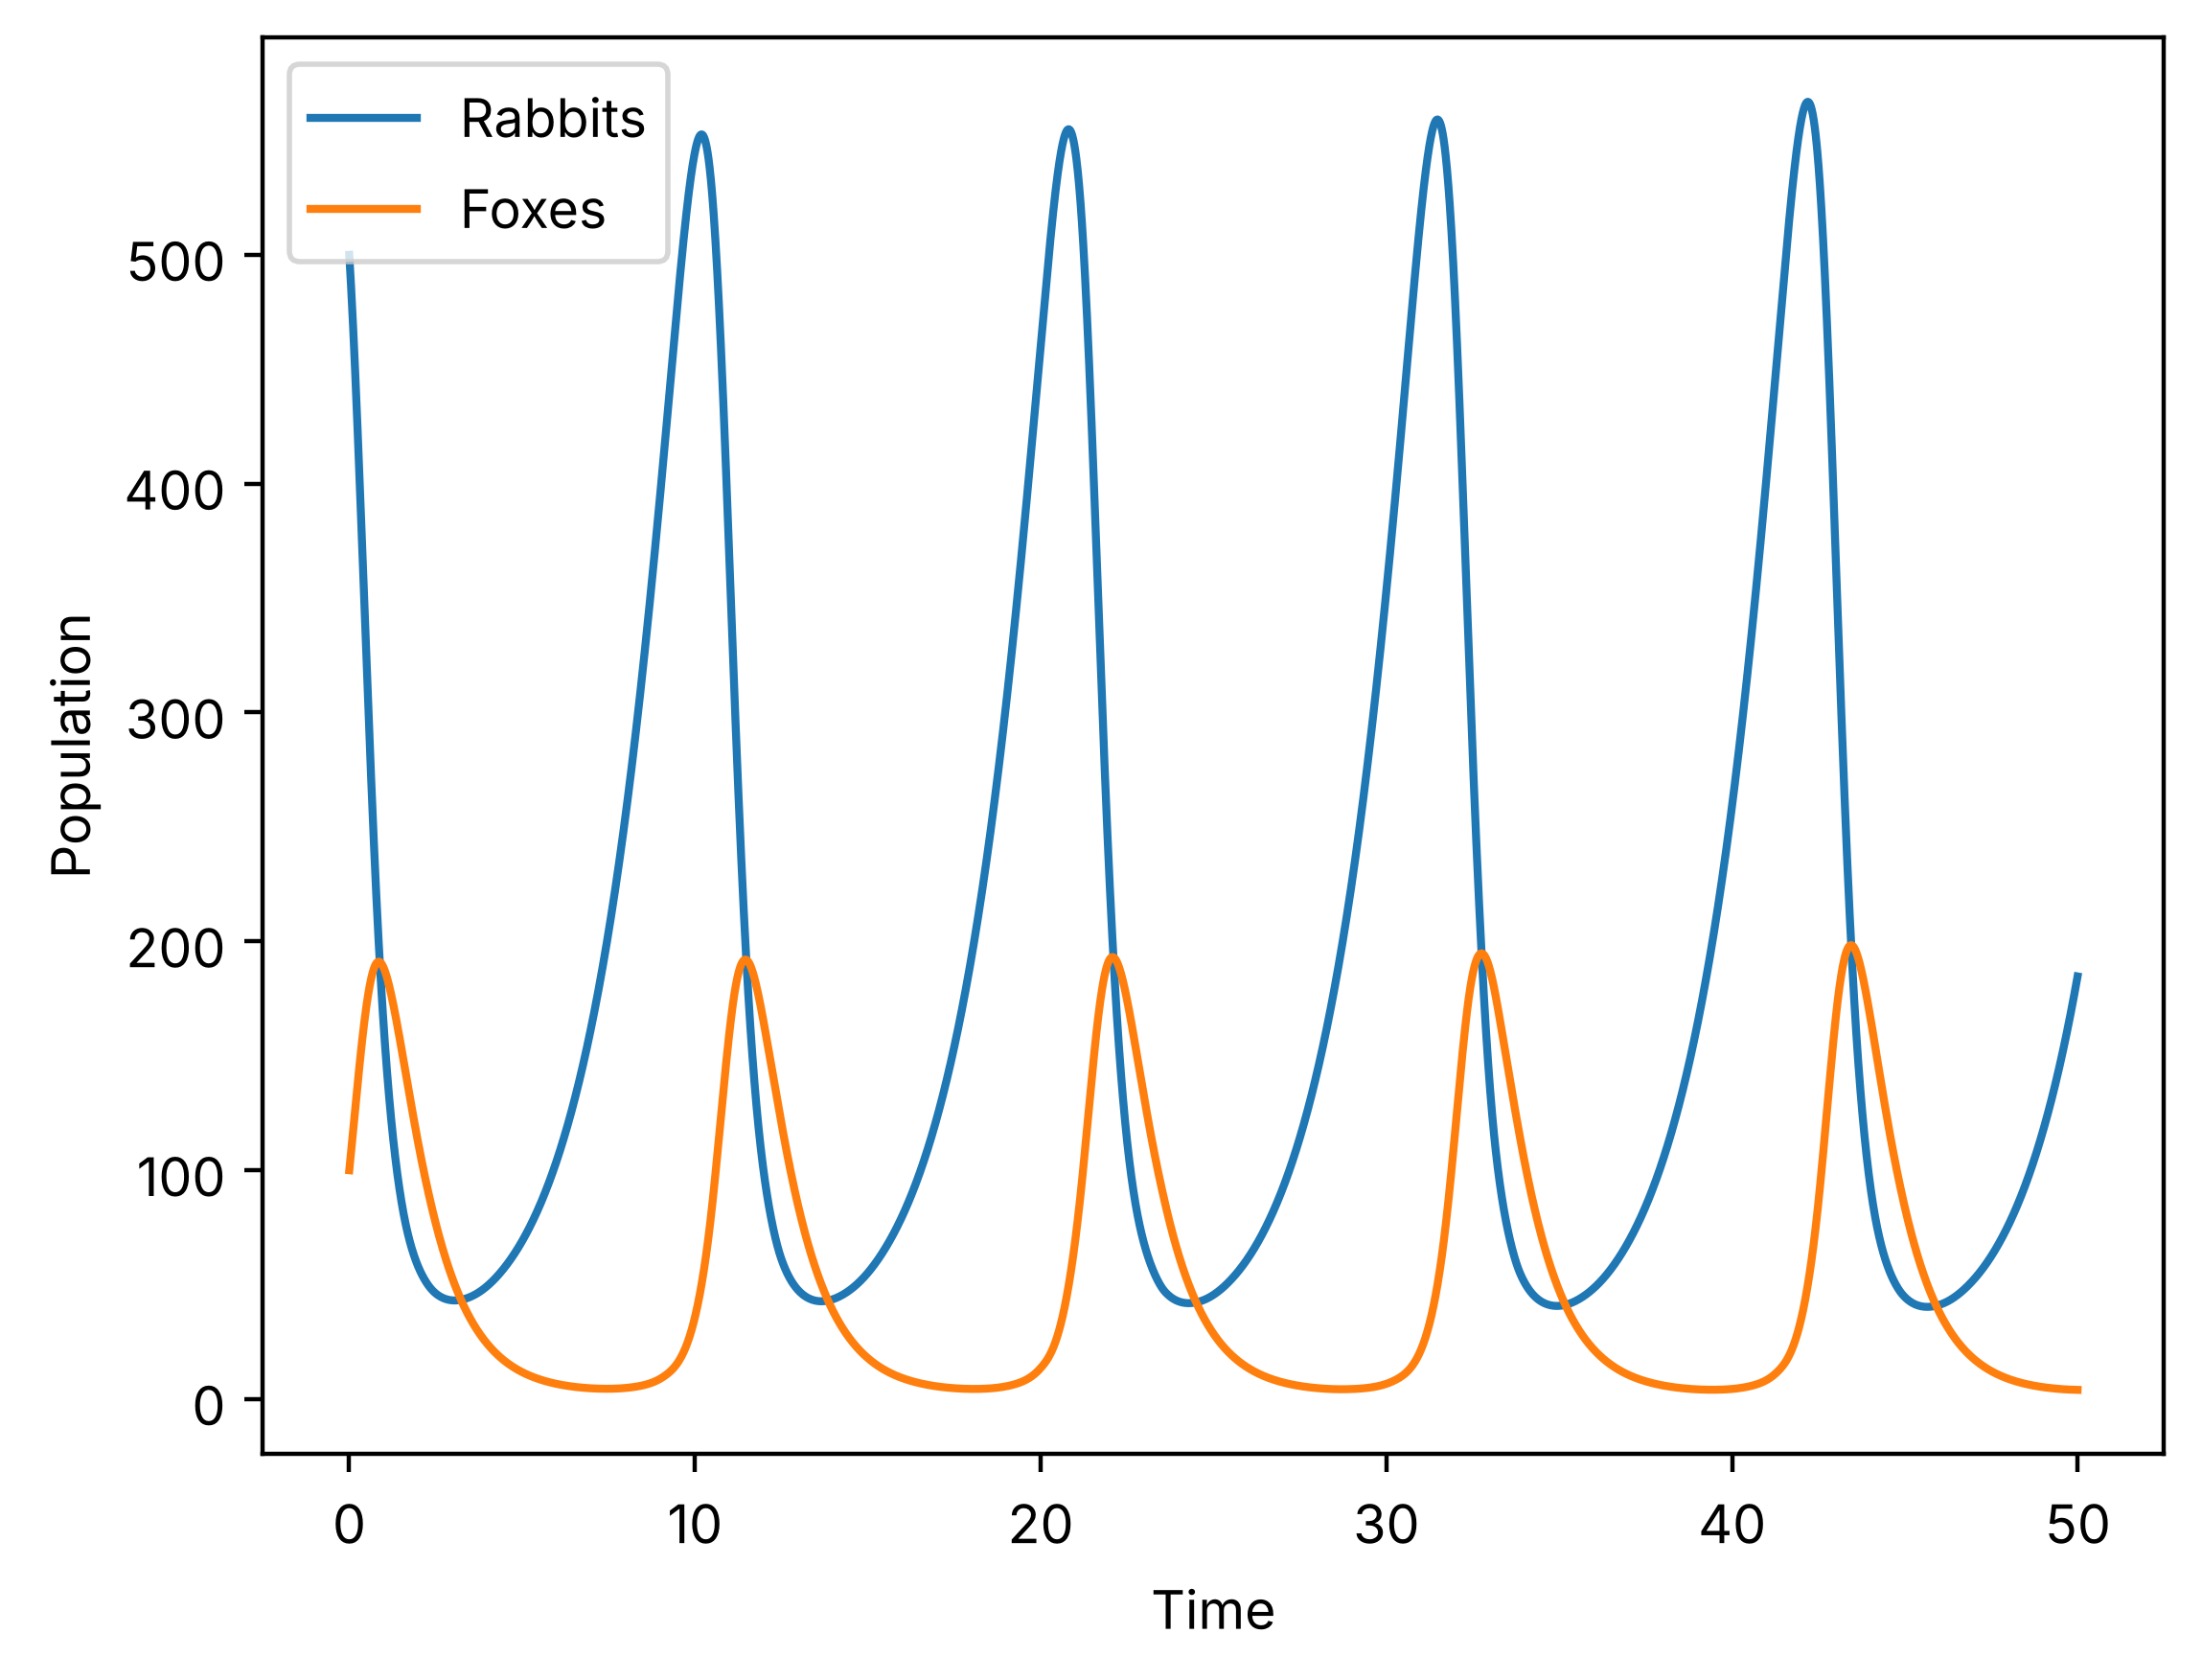

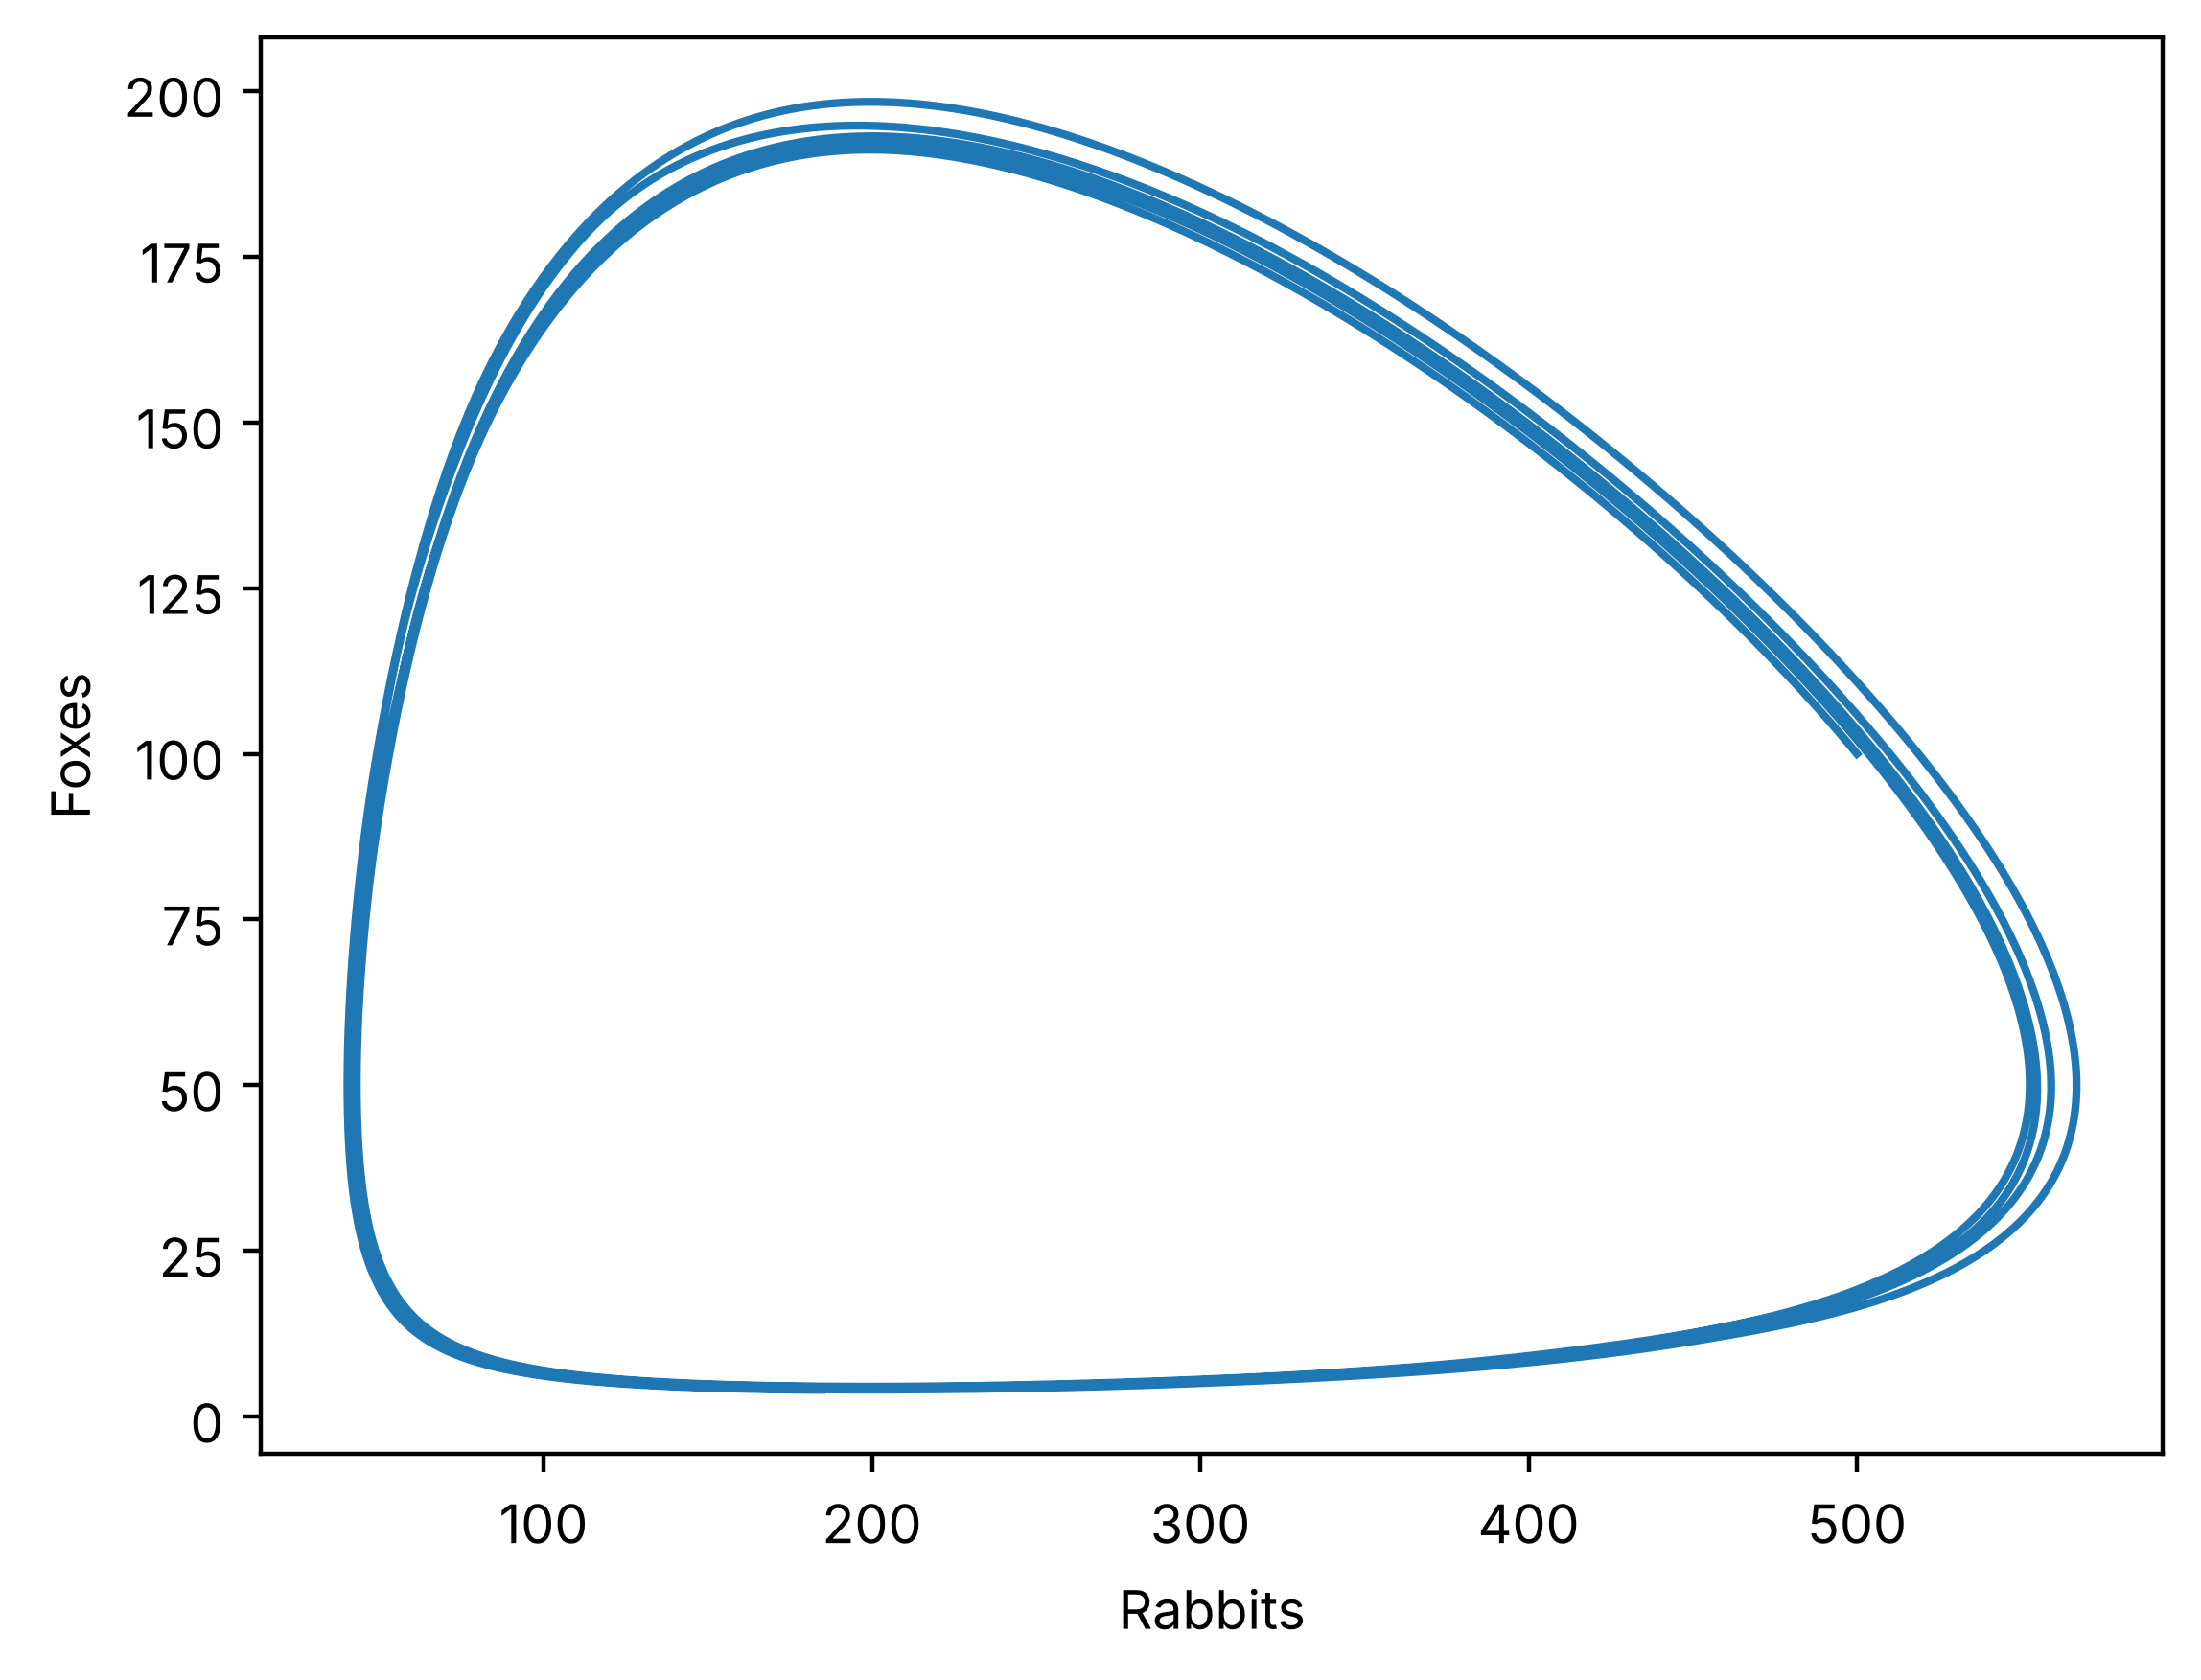

In [5]:
# --- plot the results  ------------
# sol.y has shape (n_variables, n_times): row 0 is rabbits, row 1 is foxes

fig, ax = plt.subplots()
ax.plot(t, sol.y[0], label='Rabbits')
ax.plot(t, sol.y[1], label='Foxes')
ax.set_xlabel('Time')
ax.set_ylabel('Population')
plt.legend()

fig, ax = plt.subplots()
ax.plot(sol.y[0], sol.y[1])
ax.set_xlabel('Rabbits')
ax.set_ylabel('Foxes');

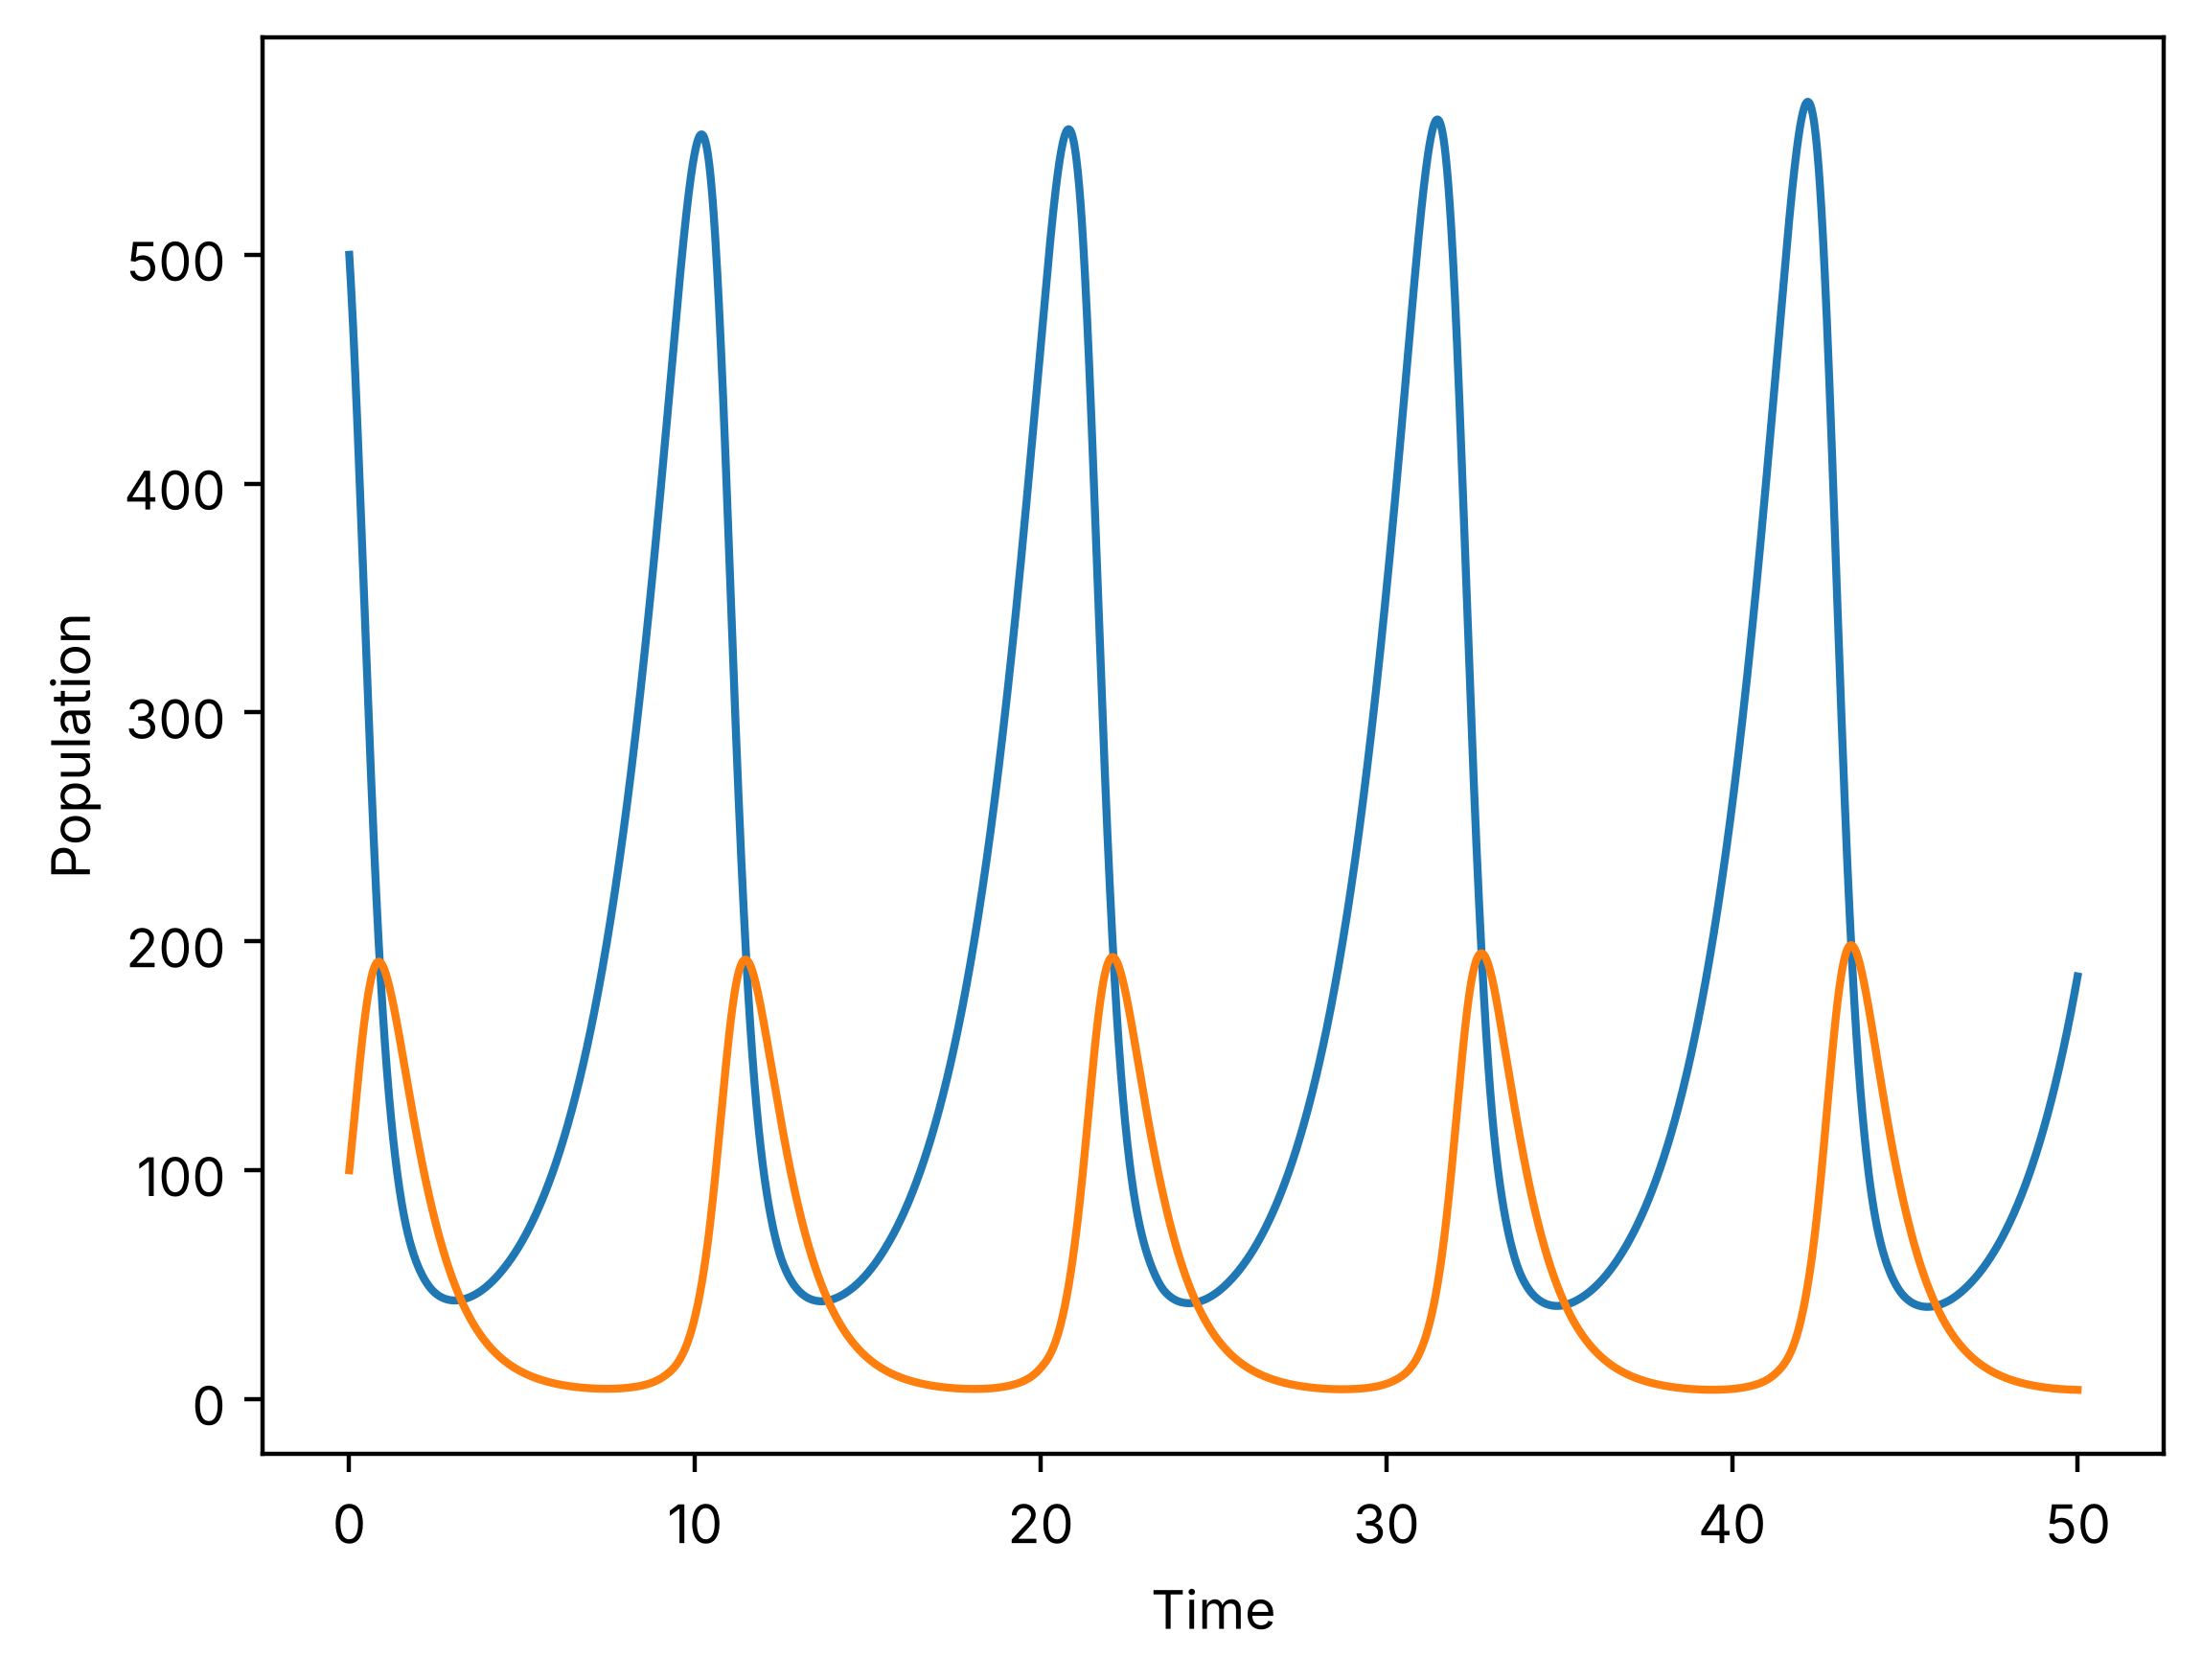

In [6]:
# --- plot the results (all in one go) ------------
# plot expects columns to be the variables, so transpose

fig, ax = plt.subplots()
ax.plot(t, sol.y.T)
ax.set_xlabel('Time')
ax.set_ylabel('Population');

## Comparing solvers
`solve_ivp` lets us choose the method. Higher-order methods take fewer, larger steps for a tight tolerance; the implicit `Radau` method is meant for stiff problems and is wasteful here.

In [7]:
# compare solvers: how many function evaluations does each need for the same tolerance?
for method in ['RK23', 'RK45', 'DOP853', 'Radau']:
    s = solve_ivp(df, (start, end), ic, method=method, rtol=1e-8, atol=1e-8)
    print(method, s.nfev)

RK23 19916
RK45 2594
DOP853 1790


Radau 12695
